# LAB MID
# Computer Vision
# Jawad Hassan
# 0035

# Task # 01

Saving capture.jpg to capture (5).jpg


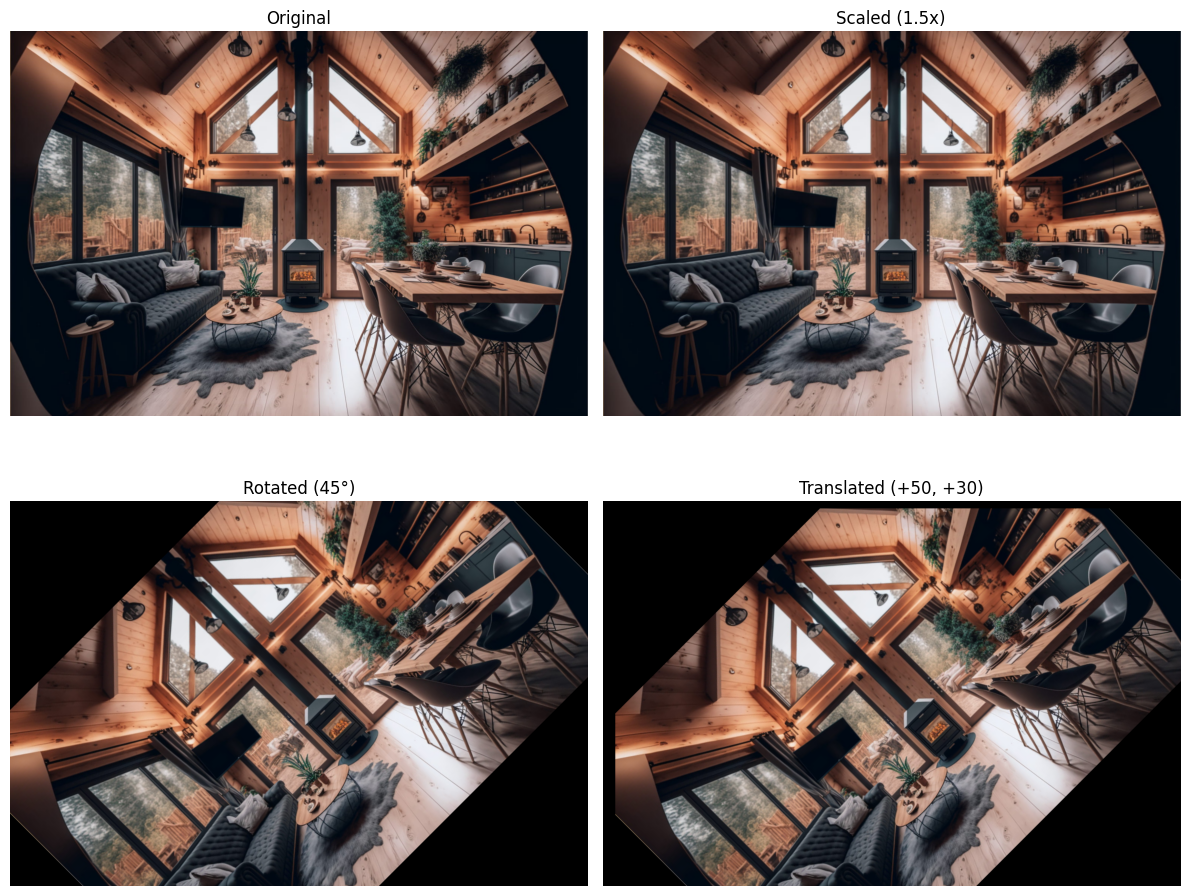

In [13]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# ---------- Step 1: Upload Image ----------
uploaded = files.upload()
image = cv2.imread('capture.jpg')

if image is None:
    print("❌ Error: Image not found.")
else:
    def bgr_to_rgb(img):
        return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # ---------- Step 2: Scale the Image by 1.5x ----------
    scaled_image = cv2.resize(image, None, fx=1.5, fy=1.5, interpolation=cv2.INTER_LINEAR)

    # ---------- Step 3: Rotate the Image by 45 Degrees ----------
    (h, w) = scaled_image.shape[:2]
    center = (w // 2, h // 2)
    rotation_matrix = cv2.getRotationMatrix2D(center, 45, 1.0)
    rotated_image = cv2.warpAffine(scaled_image, rotation_matrix, (w, h))

    # ---------- Step 4: Translate the Image (50px right, 30px down) ----------
    tx, ty = 50, 30
    translation_matrix = np.float32([[1, 0, tx], [0, 1, ty]])
    translated_image = cv2.warpAffine(rotated_image, translation_matrix, (w + tx, h + ty))

    # ---------- Display Images in 2x2 Grid ----------
    images = [image, scaled_image, rotated_image, translated_image]
    titles = ["Original", "Scaled (1.5x)", "Rotated (45°)", "Translated (+50, +30)"]

    plt.figure(figsize=(12, 10))
    for i in range(4):
        plt.subplot(2, 2, i + 1)
        plt.imshow(bgr_to_rgb(images[i]))
        plt.title(titles[i])
        plt.axis('off')
    plt.tight_layout()
    plt.show()


# Task # 02

Saving capture.jpg to capture (3).jpg


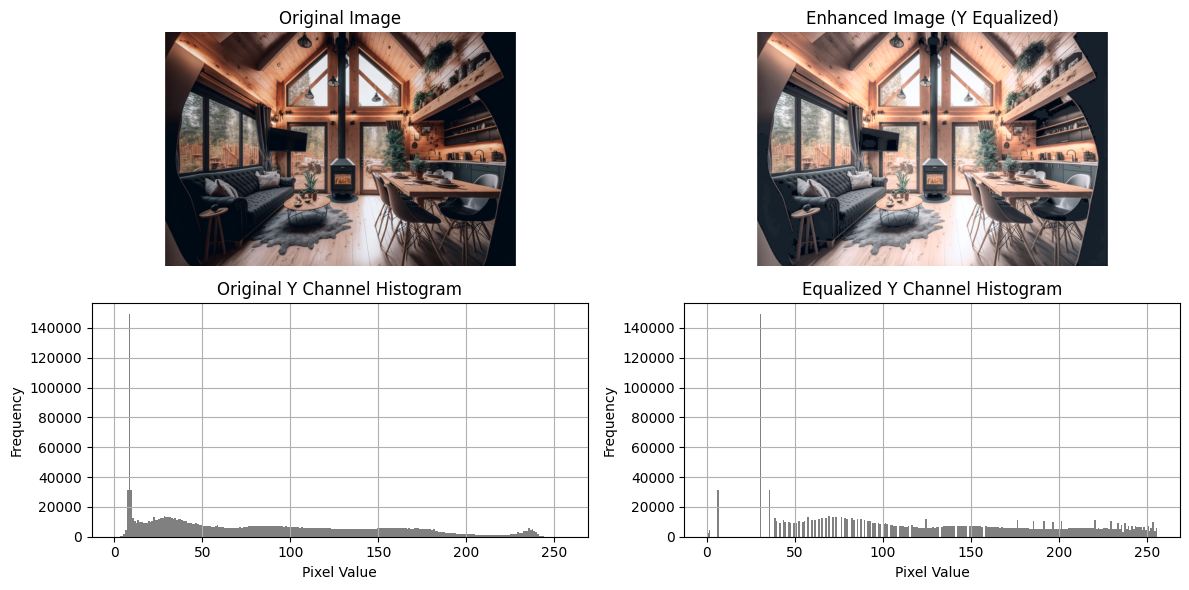

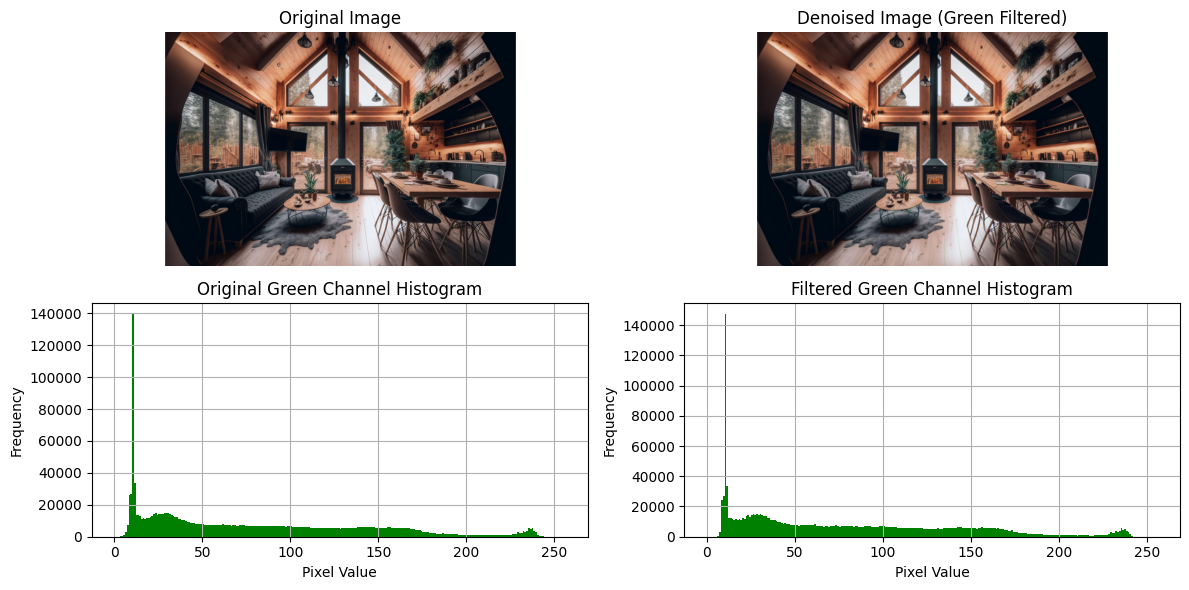

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# ---------- Step 1: Upload the Color Image ----------
uploaded = files.upload()
image = cv2.imread('capture.jpg')

if image is None:
    print("❌ Error: Image not found.")
else:
    def bgr_to_rgb(img):
        return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    def plot_image_histogram_side_by_side(img1, img2, title1, title2, hist_data1, hist_data2, color='gray', hist_title1="", hist_title2=""):
        plt.figure(figsize=(12, 6))

        # Images
        plt.subplot(2, 2, 1)
        plt.imshow(bgr_to_rgb(img1))
        plt.title(title1)
        plt.axis('off')

        plt.subplot(2, 2, 2)
        plt.imshow(bgr_to_rgb(img2))
        plt.title(title2)
        plt.axis('off')

        # Histograms
        plt.subplot(2, 2, 3)
        plt.hist(hist_data1.ravel(), bins=256, range=[0, 256], color=color)
        plt.title(hist_title1)
        plt.xlabel('Pixel Value')
        plt.ylabel('Frequency')
        plt.grid(True)

        plt.subplot(2, 2, 4)
        plt.hist(hist_data2.ravel(), bins=256, range=[0, 256], color=color)
        plt.title(hist_title2)
        plt.xlabel('Pixel Value')
        plt.ylabel('Frequency')
        plt.grid(True)

        plt.tight_layout()
        plt.show()

    # -------------------- a. Y Channel Enhancement --------------------
    ycrcb = cv2.cvtColor(image, cv2.COLOR_BGR2YCrCb)
    y, cr, cb = cv2.split(ycrcb)
    y_eq = cv2.equalizeHist(y)
    ycrcb_eq = cv2.merge((y_eq, cr, cb))
    enhanced_img = cv2.cvtColor(ycrcb_eq, cv2.COLOR_YCrCb2BGR)

    plot_image_histogram_side_by_side(
        image, enhanced_img,
        "Original Image", "Enhanced Image (Y Equalized)",
        y, y_eq,
        color='gray',
        hist_title1="Original Y Channel Histogram",
        hist_title2="Equalized Y Channel Histogram"
    )

    # -------------------- b. Green Channel Median Filtering --------------------
    b, g, r = cv2.split(image)
    g_denoised = cv2.medianBlur(g, 5)
    denoised_img = cv2.merge((b, g_denoised, r))

    plot_image_histogram_side_by_side(
        image, denoised_img,
        "Original Image", "Denoised Image (Green Filtered)",
        g, g_denoised,
        color='green',
        hist_title1="Original Green Channel Histogram",
        hist_title2="Filtered Green Channel Histogram"
    )


# Task # 3

Saving capture.jpg to capture (9).jpg


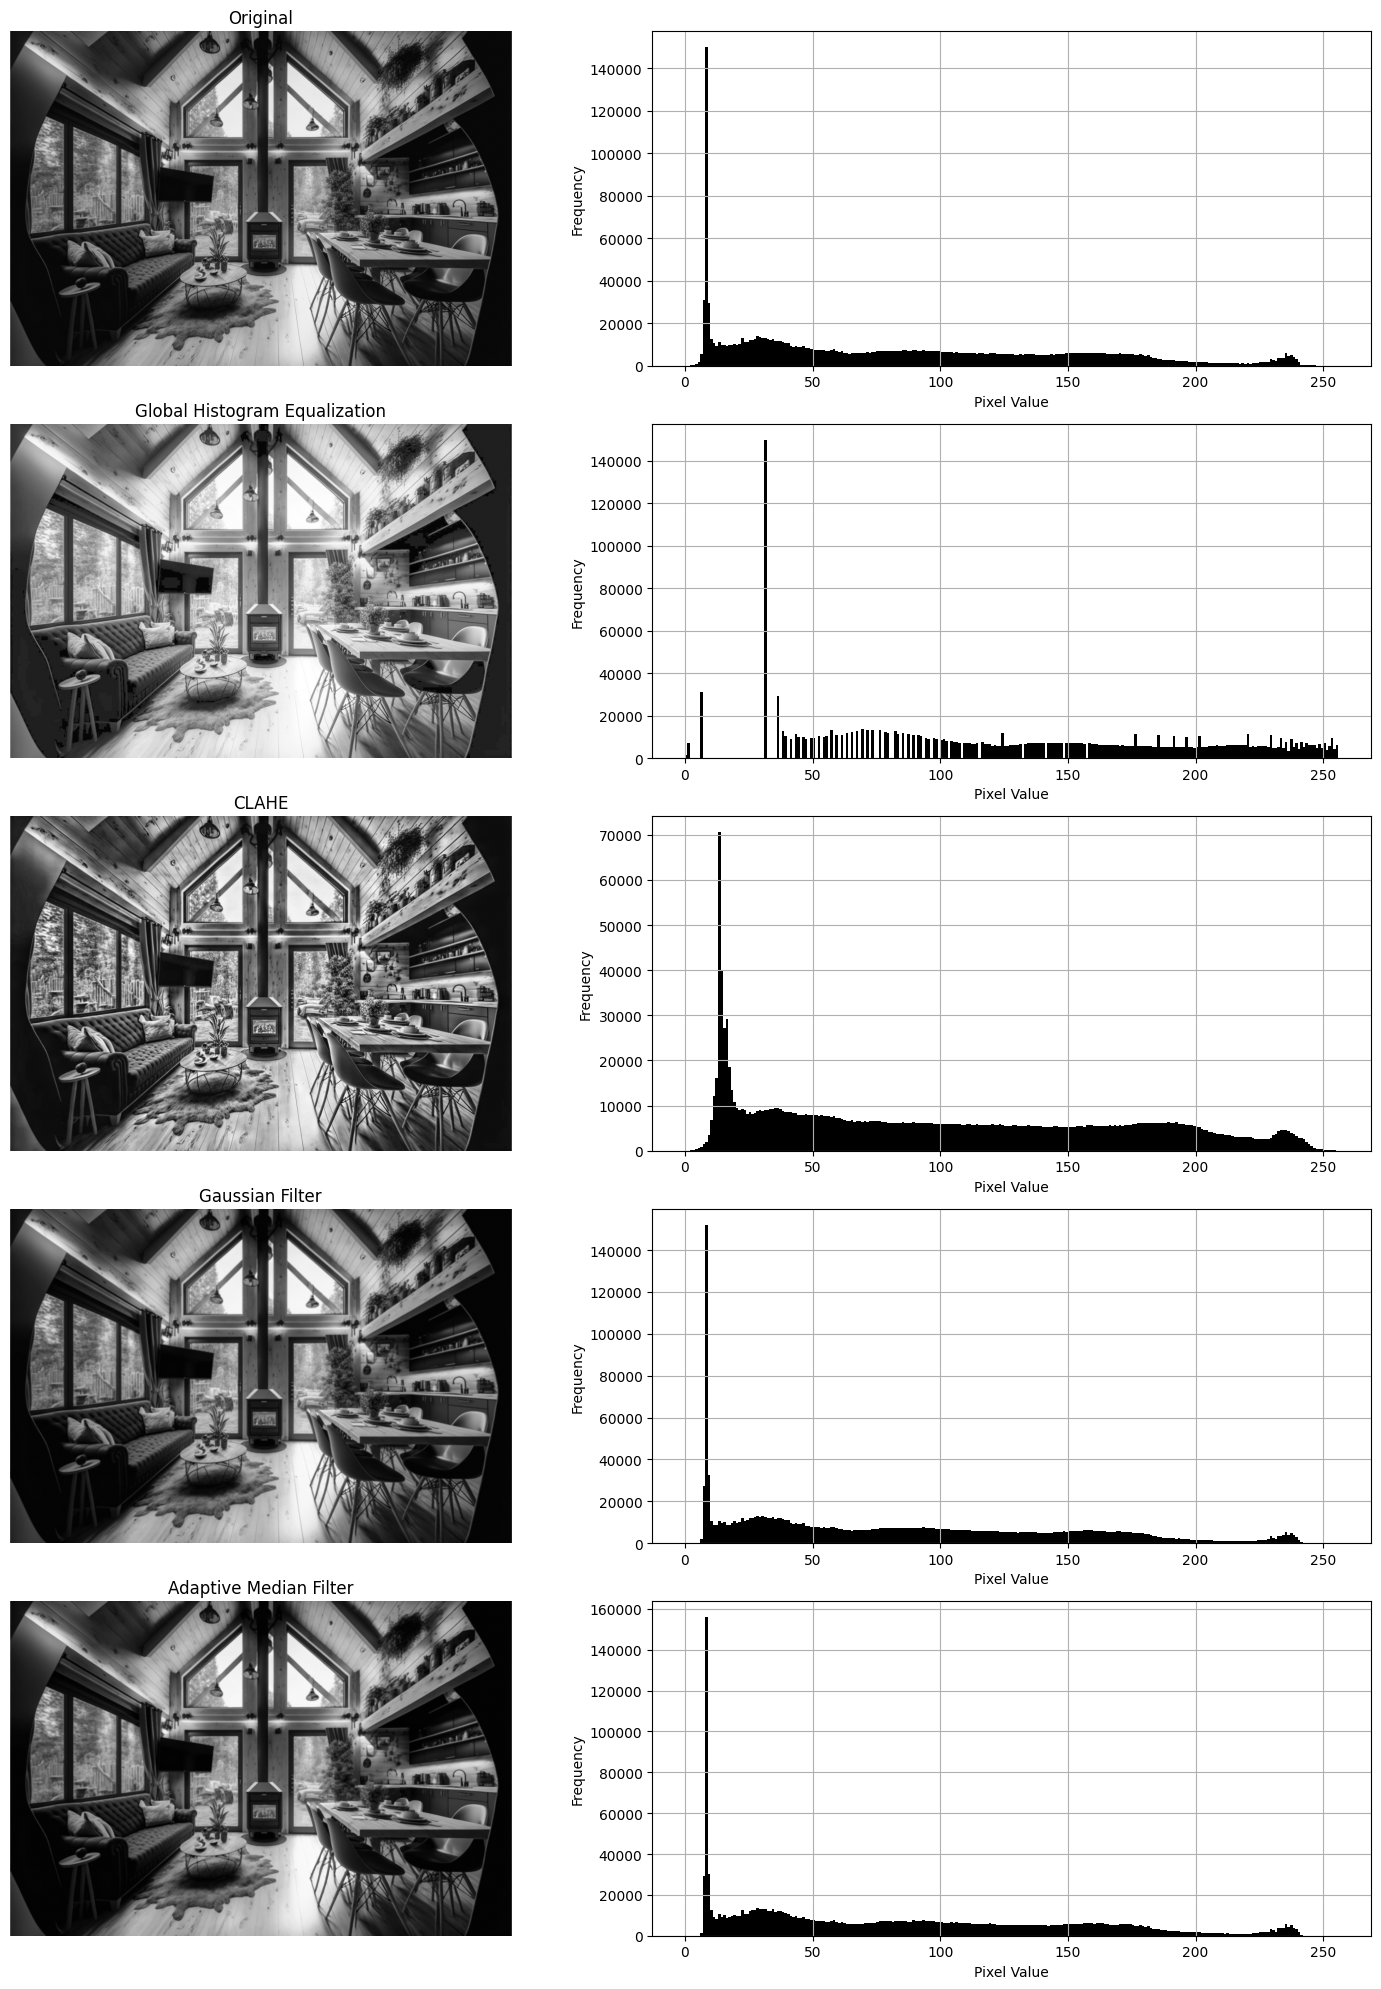

In [17]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# ---------- Step 1: Upload Image ----------
uploaded = files.upload()
image = cv2.imread('capture.jpg', cv2.IMREAD_GRAYSCALE)  # Load as grayscale

if image is None:
    print("❌ Error: Image not found.")
else:
    def show_img_and_hist(title, img, ax_img, ax_hist, cmap='gray'):
        # Show image
        ax_img.imshow(img, cmap=cmap)
        ax_img.set_title(title)
        ax_img.axis('off')

        # Show histogram
        ax_hist.hist(img.ravel(), bins=256, range=[0, 256], color='black')
        ax_hist.set_xlabel('Pixel Value')
        ax_hist.set_ylabel('Frequency')
        ax_hist.grid(True)

    # ---------- Step 2: Apply Global Histogram Equalization ----------
    hist_eq_image = cv2.equalizeHist(image)

    # ---------- Step 3: Apply CLAHE (Contrast Limited Adaptive Histogram Equalization) ----------
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(50, 50))
    clahe_image = clahe.apply(image)

    # ---------- Step 4: Apply Gaussian Filter ----------
    gaussian_image = cv2.GaussianBlur(image, (5, 5), 0)

    # ---------- Step 5: Apply Adaptive Median Filter ----------
    adaptive_median_image = cv2.medianBlur(image, 5)

    # ---------- Step 6: Display Results Side by Side with Histograms ----------
    images = [image, hist_eq_image, clahe_image, gaussian_image, adaptive_median_image]
    titles = ["Original", "Global Histogram Equalization", "CLAHE", "Gaussian Filter", "Adaptive Median Filter"]

    # Create figure with subplots for images and histograms
    fig, axes = plt.subplots(5, 2, figsize=(15, 20))

    for i in range(5):
        # Display image and histogram side by side
        show_img_and_hist(titles[i], images[i], axes[i, 0], axes[i, 1])

    plt.tight_layout()
    plt.show()


# Task # 4

Saving capture.jpg to capture (11).jpg


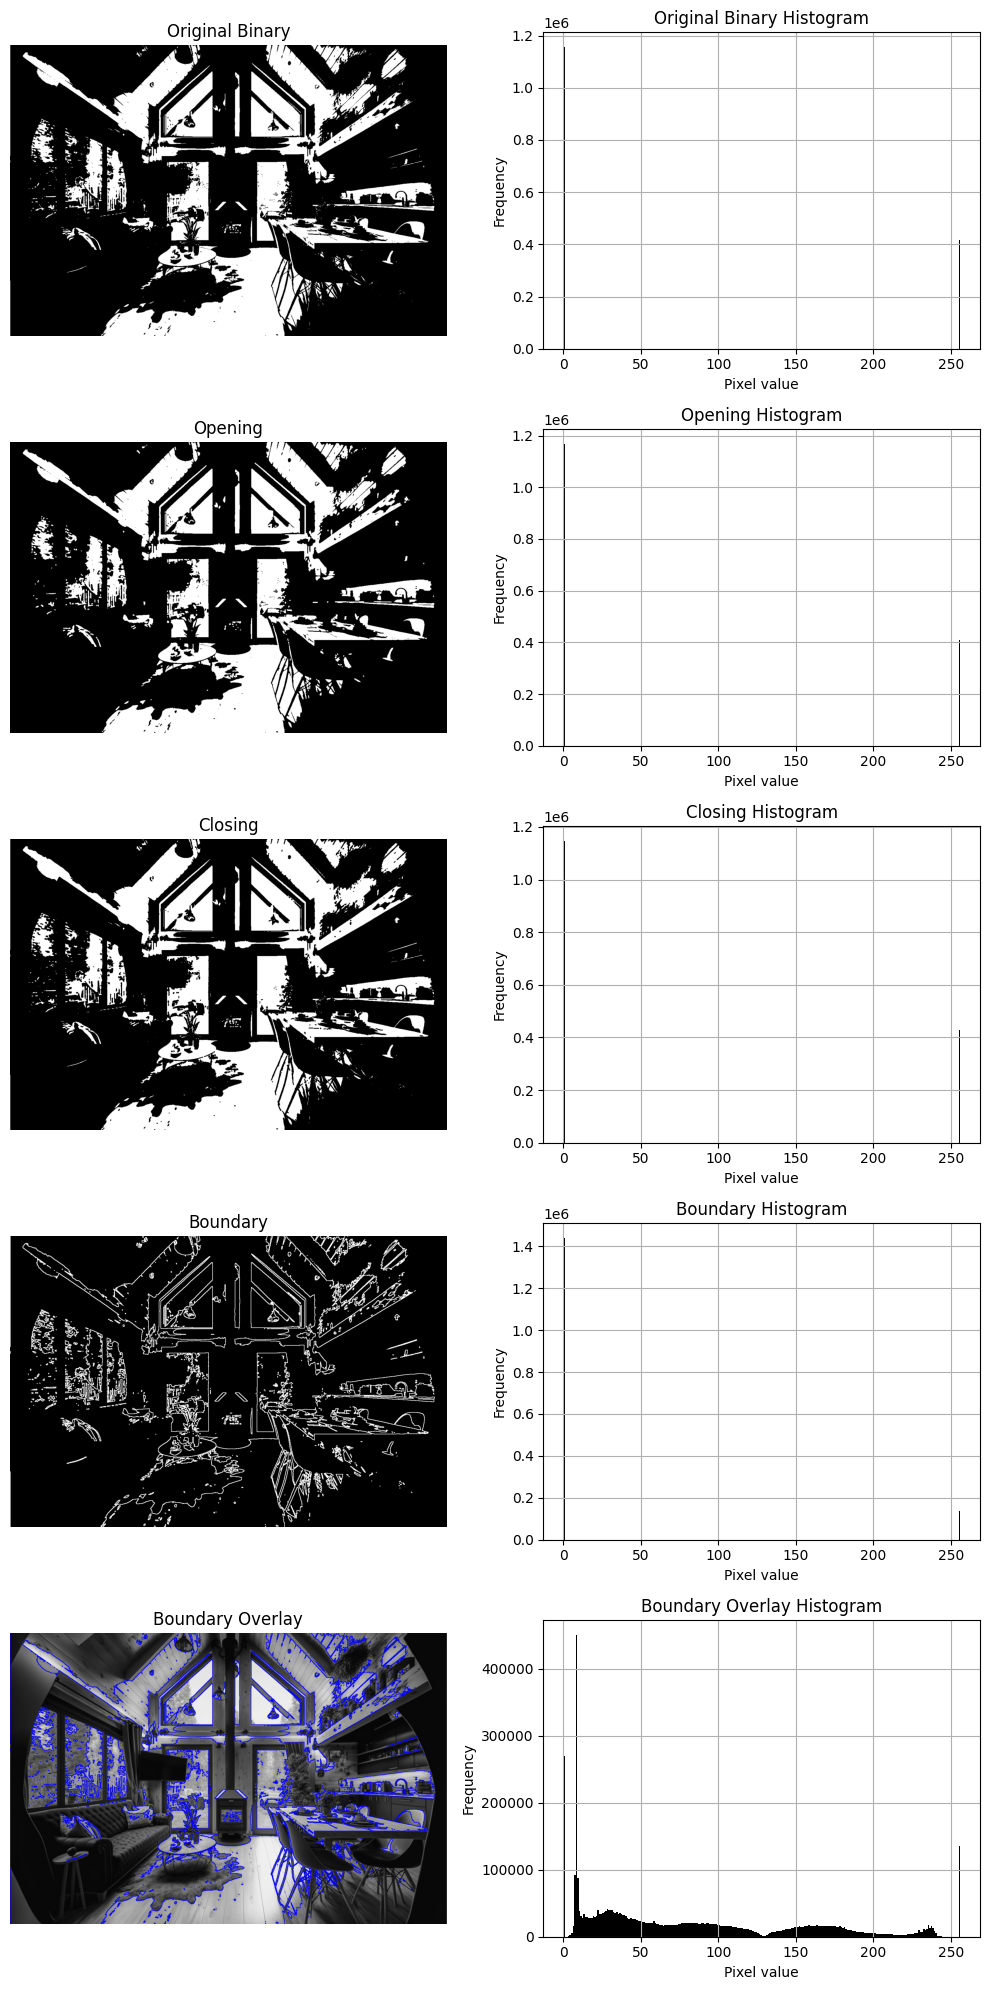

In [19]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# ---------- Step 1: Upload & Load Image ----------
uploaded = files.upload()
image = cv2.imread('capture.jpg', cv2.IMREAD_GRAYSCALE)
if image is None:
    raise ValueError("Image not found – make sure you uploaded 'capture.jpg'.")

# ---------- Step 2: Binarize ----------
_, binary = cv2.threshold(image, 128, 255, cv2.THRESH_BINARY)

# ---------- Step 3: Define Structuring Element ----------
kernel = np.ones((3,3), np.uint8)

# ---------- Step 4: Opening & Closing ----------
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN,  kernel)
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

# ---------- Step 5: Boundary Extraction ----------
dilated = cv2.dilate(binary, kernel, iterations=1)
eroded  = cv2.erode (binary, kernel, iterations=1)
boundary = cv2.subtract(dilated, eroded)

# Overlay boundary in red on the original gray image
overlay = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)
overlay[boundary==255] = [255, 0, 0]  # mark boundary pixels in red

# ---------- Step 6: Prepare for Display ----------
results = [
    (binary,   "Original Binary"),
    (opening,  "Opening"),
    (closing,  "Closing"),
    (boundary, "Boundary"),
    (overlay,  "Boundary Overlay")
]

# ---------- Step 7: Plot Images + Histograms ----------
fig, axes = plt.subplots(len(results), 2, figsize=(10, 4*len(results)))
for i, (img, title) in enumerate(results):
    # image display
    ax_img = axes[i,0]
    if img.ndim == 2:
        ax_img.imshow(img, cmap='gray')
    else:
        ax_img.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax_img.set_title(title)
    ax_img.axis('off')

    # histogram
    ax_hist = axes[i,1]
    ax_hist.hist(img.ravel(), bins=256, range=(0,256), color='black')
    ax_hist.set_title(f"{title} Histogram")
    ax_hist.set_xlabel("Pixel value")
    ax_hist.set_ylabel("Frequency")
    ax_hist.grid(True)

plt.tight_layout()
plt.show()


# Task # 5

Please upload two files: one grayscale image (sobel) and one color image (watershed).


Saving capture.jpg to capture (16).jpg


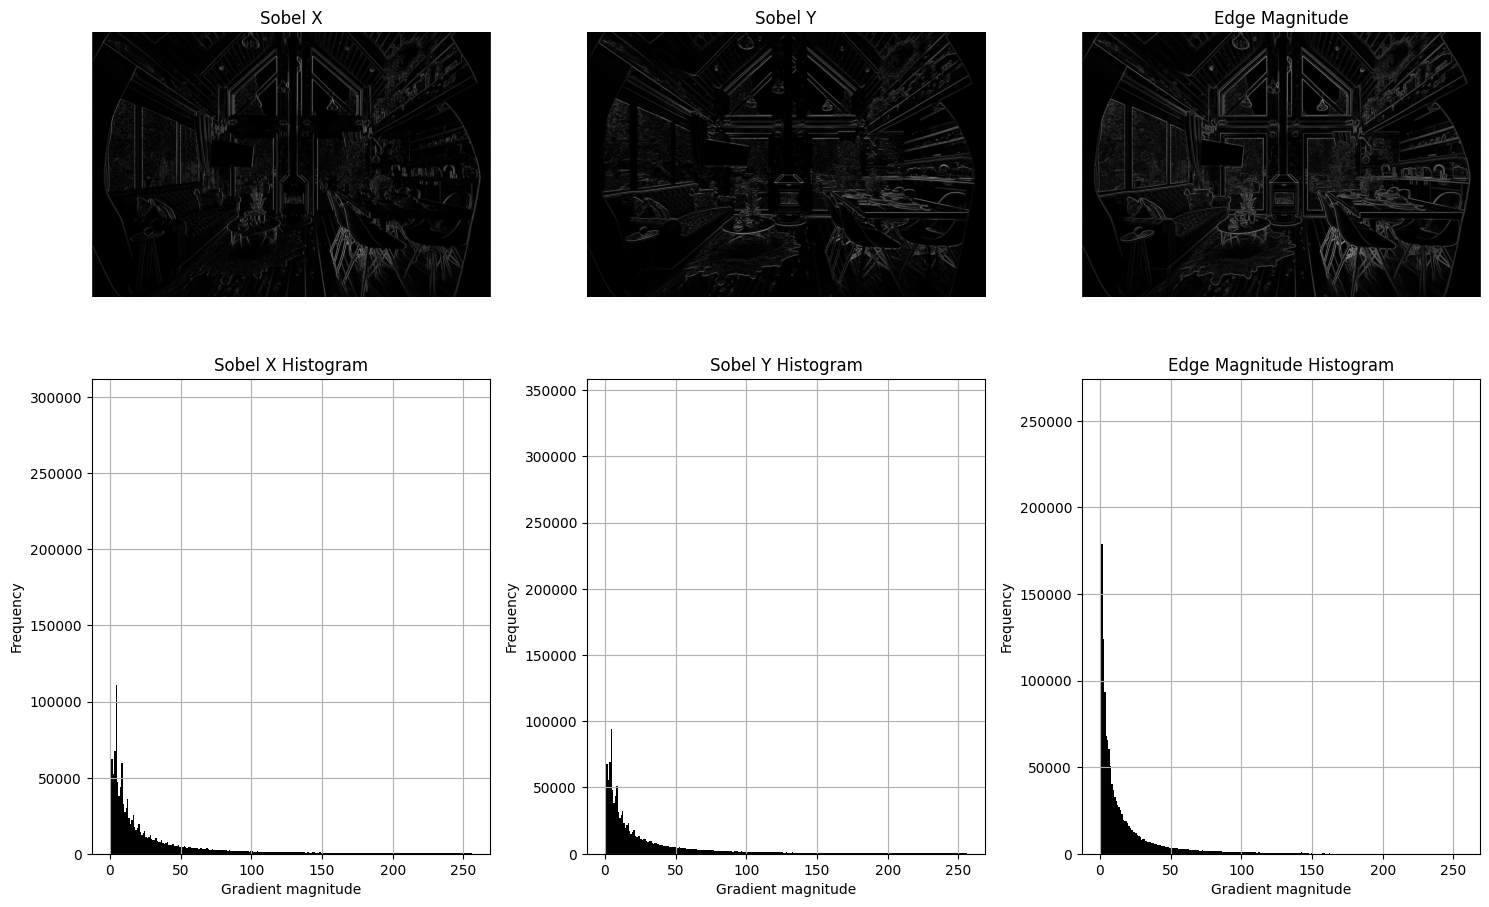

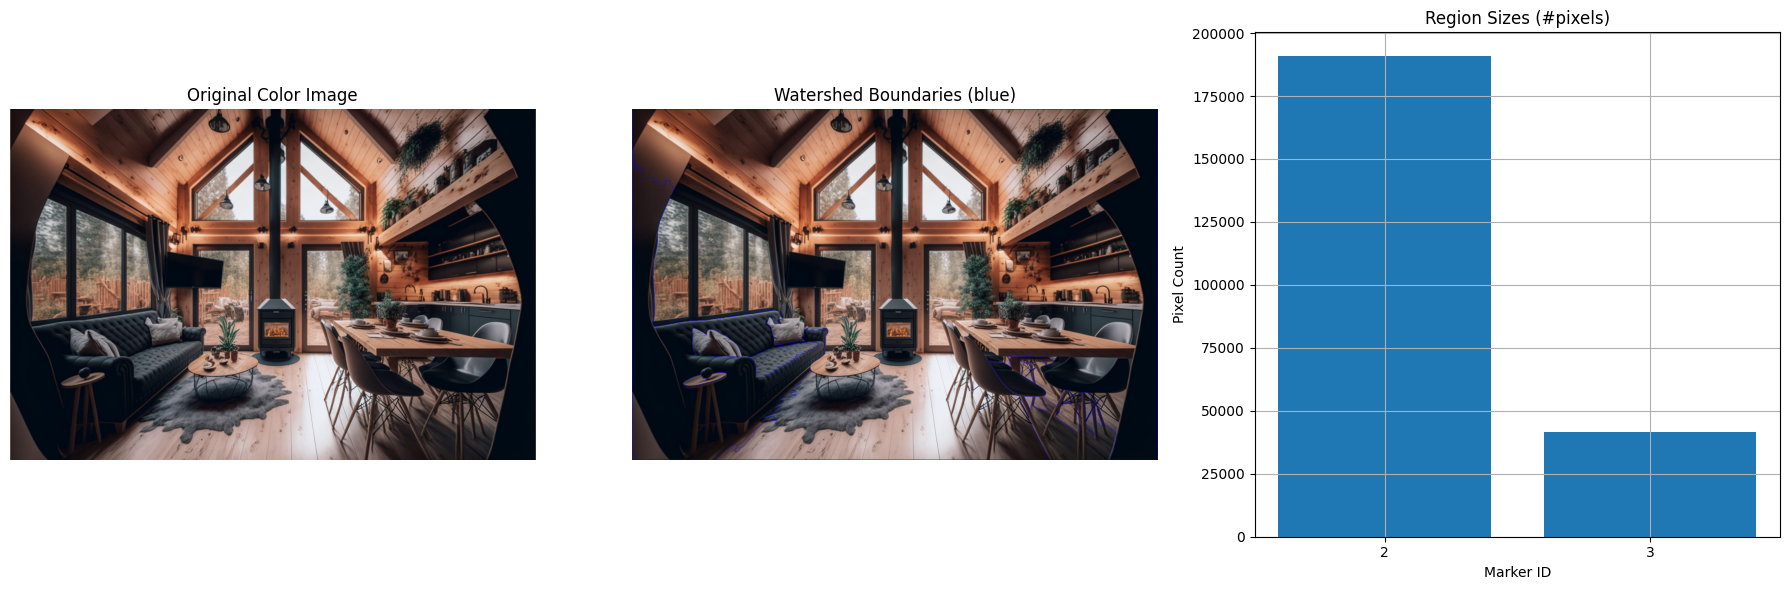

In [24]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# ---------- Step 1: Upload & Load Images ----------
print("Please upload two files: one grayscale image (sobel) and one color image (watershed).")
uploaded = files.upload()
sobel_img = cv2.imread('capture.jpg', cv2.IMREAD_GRAYSCALE)
ws_img    = cv2.imread('capture.jpg')  # color

if sobel_img is None or ws_img is None:
    raise ValueError("Make sure you uploaded 'sobel.jpg' (grayscale) and 'watershed.jpg' (color).")

# ----------------------------------------------------------------
# a. Sobel Edge Detection + Histograms
# ----------------------------------------------------------------
# 1) Compute Sobel in X and Y
sobel_x = cv2.Sobel(sobel_img, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(sobel_img, cv2.CV_64F, 0, 1, ksize=3)

# 2) Compute edge magnitude
magnitude = cv2.magnitude(sobel_x, sobel_y)
mag_norm = cv2.normalize(magnitude, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# 3) Plot images and histograms
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
titles = ['Sobel X', 'Sobel Y', 'Edge Magnitude']
imgs   = [sobel_x, sobel_y, mag_norm]

for i, img in enumerate(imgs):
    # Display gradient image
    ax_img = axes[0, i]
    ax_img.imshow(np.abs(img), cmap='gray')
    ax_img.set_title(titles[i])
    ax_img.axis('off')

    # Display histogram of absolute values
    ax_hist = axes[1, i]
    ax_hist.hist(np.abs(img).ravel(), bins=256, range=(0,256), color='black')
    ax_hist.set_title(f"{titles[i]} Histogram")
    ax_hist.set_xlabel('Gradient magnitude')
    ax_hist.set_ylabel('Frequency')
    ax_hist.grid(True)

plt.tight_layout()
plt.show()


# ----------------------------------------------------------------
# b. Watershed Segmentation + Region‐Size Bar Chart
# ----------------------------------------------------------------
def to_rgb(img): return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# 1) Pre‑processing
gray_ws = cv2.cvtColor(ws_img, cv2.COLOR_BGR2GRAY)
_, thresh = cv2.threshold(gray_ws, 0, 255,
                          cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
kernel = np.ones((3,3), np.uint8)
opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=2)

# 2) Sure background & foreground
sure_bg = cv2.dilate(opening, kernel, iterations=3)
dist   = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
_, sure_fg = cv2.threshold(dist, 0.7*dist.max(), 255, 0)
sure_fg = np.uint8(sure_fg)
unknown = cv2.subtract(sure_bg, sure_fg)

# 3) Marker labelling
_, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown==255] = 0

# 4) Watershed
markers = cv2.watershed(ws_img, markers)
ws_result = ws_img.copy()
ws_result[markers == -1] = [255, 0, 0]  # red boundaries

# 5) Compute region‐sizes (exclude background=1 and boundaries=-1)
labels, counts = np.unique(markers, return_counts=True)
mask = (labels > 1)  # only real object labels
region_labels = labels[mask]
region_sizes  = counts[mask]

# 6) Display original vs watershed & bar chart
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18,6))

ax1.imshow(to_rgb(ws_img))
ax1.set_title('Original Color Image')
ax1.axis('off')

ax2.imshow(to_rgb(ws_result))
ax2.set_title('Watershed Boundaries (blue)')
ax2.axis('off')

ax3.bar(region_labels.astype(str), region_sizes, color='tab:blue')
ax3.set_title('Region Sizes (#pixels)')
ax3.set_xlabel('Marker ID')
ax3.set_ylabel('Pixel Count')
ax3.grid(True)

plt.tight_layout()
plt.show()


# Task # 6

Saving capture.jpg to capture (21).jpg


<ipython-input-29-42e9b0fe9960>:71: UserWarning: Glyph 8419 (\N{COMBINING ENCLOSING KEYCAP}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


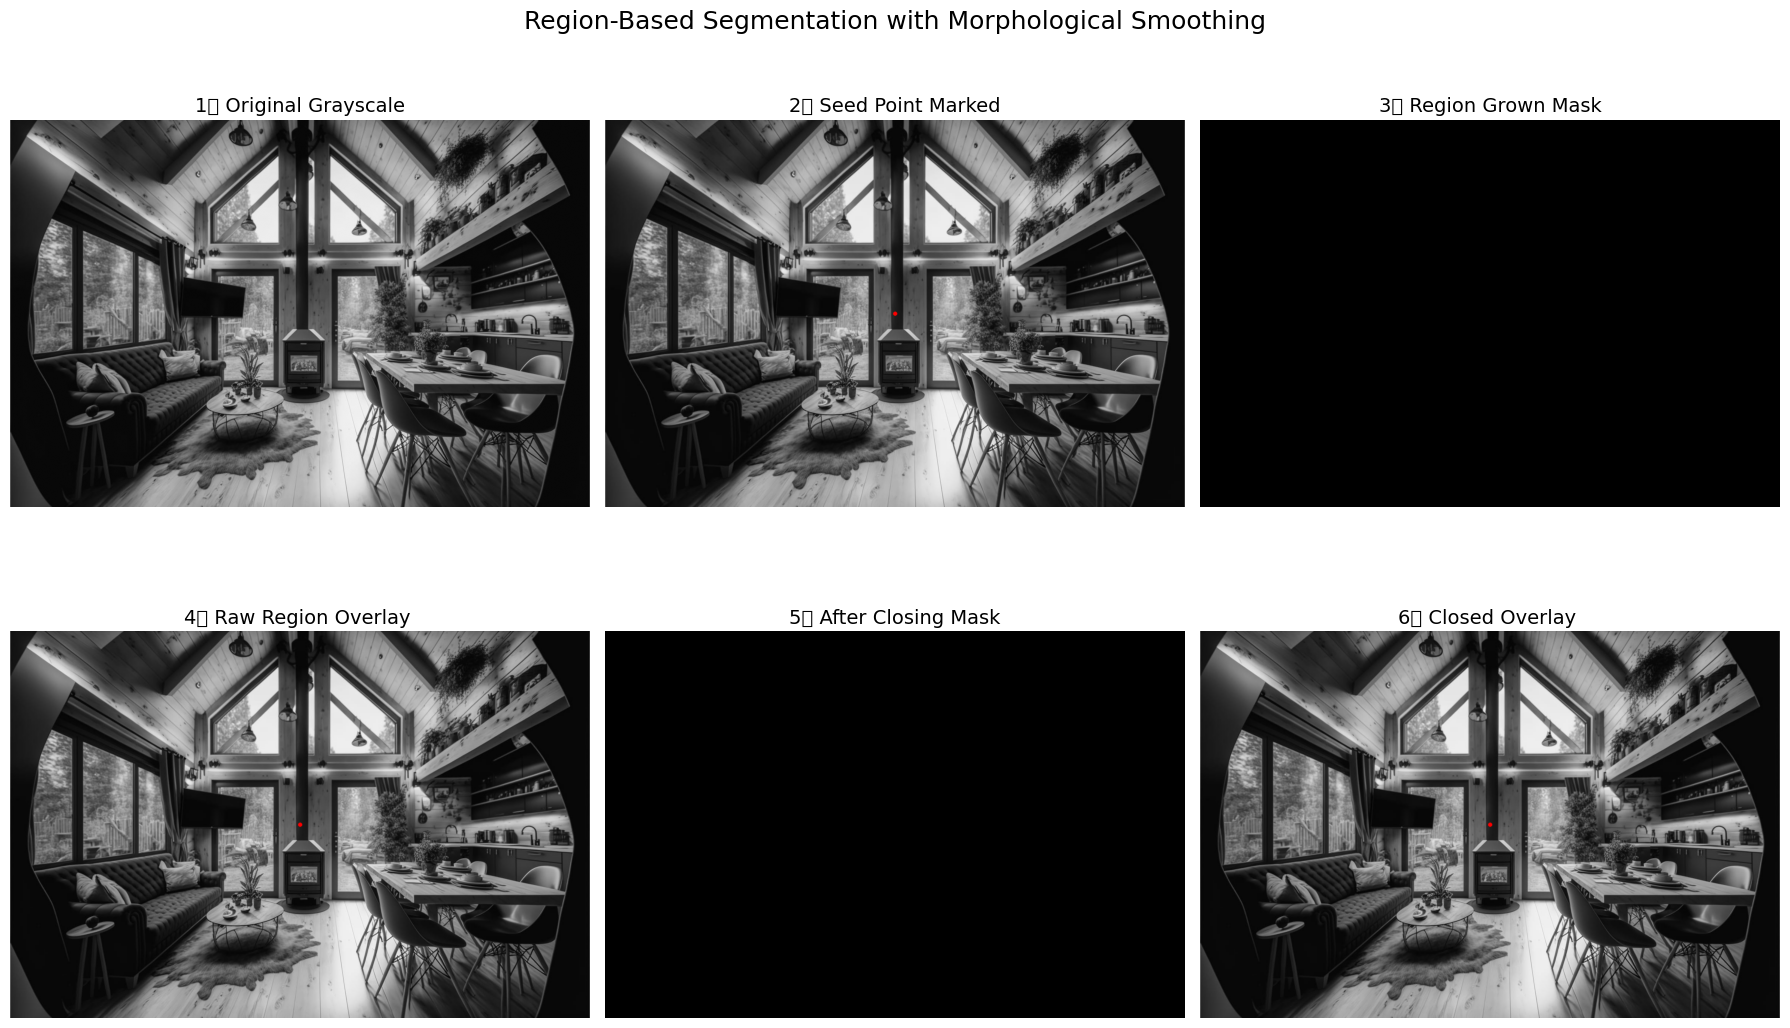

In [29]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# ---------- Step 1: Upload & Load Grayscale Image ----------
uploaded = files.upload()
fn = list(uploaded.keys())[0]
gray = cv2.imread(fn, cv2.IMREAD_GRAYSCALE)
if gray is None:
    raise ValueError("Failed to load image. Make sure it's a valid grayscale image.")

h, w = gray.shape

# ---------- Step 2: Mark Seed Point ----------
# You can change this to any (x, y) inside the image
seed_point = (w//2, h//2)
seed_marked = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)
cv2.circle(seed_marked, seed_point, 5, (0, 0, 255), -1, lineType=cv2.LINE_AA)

# ---------- Step 3: Region Growing via floodFill ----------
mask = np.zeros((h+2, w+2), np.uint8)
flood_img = gray.copy()
# loDiff, upDiff control allowed intensity variation
cv2.floodFill(flood_img, mask, seed_point, 255, loDiff=(10,)*3, upDiff=(10,)*3,
              flags=cv2.FLOODFILL_MASK_ONLY | (255<<8))
# extract region: mask==1 gives the filled area
region_mask = (mask[1:-1,1:-1] == 1).astype(np.uint8) * 255

# overlay the raw grown region in green
overlay_raw = seed_marked.copy()
overlay_raw[region_mask == 255] = (0, 255, 0)

# ---------- Step 4: Morphological Closing to Smooth Boundary ----------
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7,7))
closed_mask = cv2.morphologyEx(region_mask, cv2.MORPH_CLOSE, kernel)

# overlay the closed region in blue
overlay_closed = seed_marked.copy()
overlay_closed[closed_mask == 255] = (255, 0, 0)

# ---------- Step 5: Display Everything in a 2×3 Grid ----------
titles = [
    "1️⃣ Original Grayscale",
    "2️⃣ Seed Point Marked",
    "3️⃣ Region Grown Mask",
    "4️⃣ Raw Region Overlay ",
    "5️⃣ After Closing Mask",
    "6️⃣ Closed Overlay "
]
images = [
    gray,
    seed_marked,
    region_mask,
    overlay_raw,
    closed_mask,
    overlay_closed
]

plt.figure(figsize=(18, 12))
for i, (img, title) in enumerate(zip(images, titles)):
    ax = plt.subplot(2, 3, i+1)
    if img.ndim == 2:
        ax.imshow(img, cmap='gray')
    else:
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title, fontsize=14)
    ax.axis('off')

plt.suptitle("Region‐Based Segmentation with Morphological Smoothing", fontsize=18, y=0.95)
plt.tight_layout()
plt.show()
